In [1]:
%pip install mlflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# MLflow connection — enter the course credentials when prompted.
# The password is hidden and neither credential is written into this notebook.
import os
from getpass import getpass
import uuid
import mlflow
from mlflow.tracking import MlflowClient

MLFLOW_TRACKING_URI = "http://10.0.100.20:5000"
MLFLOW_TRACKING_USERNAME = "csc-4933-001-user04"
MLFLOW_TRACKING_PASSWORD = "UgayBUfg7mwnNFrp"
os.environ["MLFLOW_TRACKING_USERNAME"] = MLFLOW_TRACKING_USERNAME
os.environ["MLFLOW_TRACKING_PASSWORD"] = MLFLOW_TRACKING_PASSWORD
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
EXECUTION_ID = uuid.uuid4().hex[:10]
REMOTE_RUN_IDS = {}
print("MLflow server:", MLFLOW_TRACKING_URI)
print("Execution ID:", EXECUTION_ID)


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow server: http://10.0.100.20:5000
Execution ID: 4d84b5b07d


# H2 Model Experiments: Does preseason rating improve tournament-success predictions?

This notebook runs the H2 experiment described in [`experiment.md`](../experiment.md). It tests whether adding preseason rating to regular-season win rate improves predictions of whether a team wins at least one main-bracket tournament game.

**Run the notebook from top to bottom once.** It uses the prepared H2 files, applies the saved walk-forward splits, compares both candidates on every validation season, selects a model using validation only, scores that selected model on the 2025 test season once, and produces unscored 2026 forecasts. It logs each run to MLflow and saves the tables, predictions, figures, and report under `results/H2/`.


## 1. Question and experiment

**Hypothesis:** If preseason ratings contain information that regular-season win rates miss, then a model using both should predict tournament success more accurately than a model using win rate alone.

The outcome is binary: `won_at_least_one_main_bracket_game` is `1` when a team won at least one main-bracket game and `0` otherwise. A team that did not enter the tournament, or entered but won no main-bracket game, has outcome `0`.

| Candidate | Input columns | What it tests |
|---|---|---|
| Win-rate-only | `regular_season_win_rate` | Reference prediction using regular-season performance. |
| Win-rate-plus-rating | `regular_season_win_rate`, `preseason_rating` | Whether preseason rating adds predictive information. |

Both candidates use the **same logistic-regression method, outcome, fold assignments, scaling method, and scoring rule**. The only planned difference is whether `preseason_rating` is included. `season` and `team_id` identify rows and splits; they are not model inputs. The outcome is never used as an input.


## 2. Data files and row meaning

The prepared files are in `prepared_data/H2/`. One row represents **one active team in one season**.

| File | How this notebook uses it |
|---|---|
| `h2_fold_data.csv` | Main modeling table. Supplies the predictors, binary outcome, and the training/validation/test label for each saved fold. |
| `h2_fold_manifest.csv` | Authoritative list of training seasons and held-out season for every fold. The code checks the rows against this file before fitting anything. |
| `h2_team_season_labeled.csv` | One copy of each labeled team-season. Used to refit models for 2026 forecasts after the final test has been scored. |
| `h2_2026_forecast_features.csv` | 2026 predictors only. It has no tournament outcome, so its forecasts cannot be scored. |

The cleaned source data and feature construction are documented in `feature_engineering_H2.ipynb`. This modeling notebook does not rebuild or alter those features.


## 3. Walk-forward validation and final test

We use **walk-forward validation** because the model is intended to predict a later season from earlier seasons. Every model gets the same seasons in each fold. Season 2020 is excluded because no tournament was held.

| Training seasons | Held-out season | Purpose |
|---|---:|---|
| 2015–2019 | 2021 | Validation fold 1 |
| 2015–2019, 2021 | 2022 | Validation fold 2 |
| 2015–2019, 2021–2022 | 2023 | Validation fold 3 |
| 2015–2019, 2021–2023 | 2024 | Validation fold 4 |
| 2015–2019, 2021–2024 | 2025 | Final test, after model selection |

For every validation fold, each candidate is fitted on the listed training seasons and evaluated on that fold's held-out season. The model is refitted separately for each fold; it is not carried over from the previous fold. We choose between the candidates by their **mean validation Brier score**. The 2025 test score does not influence that choice. The selected candidate is fitted on 2015–2024 and scored on 2025 once.

After the final test, both candidates are refitted on all labeled seasons through 2025 to produce 2026 forecasts. This later refit uses the known 2025 outcome to prepare a model for the next season; it does not change or replace the one-time 2025 test result. 2026 has no tournament label, so those outputs are forecasts only.


## 4. How we score probability predictions

Logistic regression returns a probability, such as `0.72` (a 72% estimated chance of at least one main-bracket win). The Brier score compares that probability with the actual `0` or `1` outcome:

\[
\text{Brier score} = (\text{actual outcome} - \text{predicted probability})^2
\]

For a predicted probability of `0.72`, an actual win (`1`) gives `(1 − 0.72)² = 0.0784`; an actual no-win (`0`) gives `(0 − 0.72)² = 0.5184`. We average the row scores within each held-out season. **Lower Brier score means better probability predictions.**

We report each validation season separately, the average and sample standard deviation across the four seasons, and the mean train–validation gap. The training Brier score is calculated on the same rows used to fit that fold's model; it is an in-sample reference, while the held-out Brier score is the validation estimate.


In [3]:
# Imports and find the project root so the notebook works from the repo root or notebooks/.
from pathlib import Path
import json
import platform
import re
import uuid
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
import mlflow
import mlflow.sklearn


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "prepared_data" / "H2").is_dir() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from the repository, "
        "which should contain prepared_data/H2/ and results/."
    )


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "prepared_data" / "H2"
RESULTS_DIR = PROJECT_ROOT / "results" / "H2"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"
FIGURES_DIR = RESULTS_DIR / "figures"
MLFLOW_DIR = PROJECT_ROOT / "mlflow" / "H2"

for directory in (RESULTS_DIR, PREDICTIONS_DIR, FIGURES_DIR, MLFLOW_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Prepared H2 data:", DATA_DIR)
print("H2 results:", RESULTS_DIR)
print("H2 MLflow store:", MLFLOW_DIR)
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__, "| MLflow:", mlflow.__version__)


Project root: c:\Users\SAMUE\Downloads\CSC_400_series\CSC 4913\Project\final-project-main\Topic4_Sports_Analytics_The_Unbeatable_Underdog\CSC-4913-Project-4
Prepared H2 data: c:\Users\SAMUE\Downloads\CSC_400_series\CSC 4913\Project\final-project-main\Topic4_Sports_Analytics_The_Unbeatable_Underdog\CSC-4913-Project-4\prepared_data\H2
H2 results: c:\Users\SAMUE\Downloads\CSC_400_series\CSC 4913\Project\final-project-main\Topic4_Sports_Analytics_The_Unbeatable_Underdog\CSC-4913-Project-4\results\H2
H2 MLflow store: c:\Users\SAMUE\Downloads\CSC_400_series\CSC 4913\Project\final-project-main\Topic4_Sports_Analytics_The_Unbeatable_Underdog\CSC-4913-Project-4\mlflow\H2
Python: 3.11.5 | pandas: 3.1.1 | scikit-learn: 1.9.1 | MLflow: 3.18.0


## 5. Load and check the prepared data

Before fitting, this section checks that required columns and labels are present, that 2020 is absent, and that each saved fold matches its manifest. A failure here means the prepared data or its folder location needs to be fixed before any model results are trusted.


In [4]:
TARGET = "won_at_least_one_main_bracket_game"
FEATURES = {
    "Win-rate-only": ["regular_season_win_rate"],
    "Win-rate-plus-rating": ["regular_season_win_rate", "preseason_rating"],
}
FOLD_COL = "fold"
ROLE_COL = "data_role"

fold_data = pd.read_csv(DATA_DIR / "h2_fold_data.csv")
manifest = pd.read_csv(DATA_DIR / "h2_fold_manifest.csv")
team_season_labeled = pd.read_csv(DATA_DIR / "h2_team_season_labeled.csv")
forecast_2026 = pd.read_csv(DATA_DIR / "h2_2026_forecast_features.csv")

required_fold_columns = [
    "season", "team_id", "regular_season_win_rate", "preseason_rating",
    TARGET, FOLD_COL, ROLE_COL,
]
missing = [column for column in required_fold_columns if column not in fold_data.columns]
assert not missing, f"h2_fold_data.csv is missing columns: {missing}"
assert {"fold", "training_seasons", "heldout_season", "heldout_role"}.issubset(manifest.columns)
assert set(fold_data[TARGET].dropna().unique()).issubset({0, 1}), "Outcome must be encoded as 0 or 1."
assert fold_data[required_fold_columns].notna().all().all(), "Model or split columns contain missing values."
assert 2020 not in set(fold_data["season"]), "Season 2020 should be excluded."
assert forecast_2026["season"].eq(2026).all(), "Forecast file should contain only 2026 rows."
assert TARGET not in forecast_2026.columns, "2026 forecast rows must not contain tournament outcomes."
assert team_season_labeled[["season", "team_id"]].duplicated().sum() == 0, "Expected one row per team-season."

# Summarize the outcome rate; tournament success is relatively uncommon, so this is useful context.
class_summary = (
    team_season_labeled.groupby("season", as_index=False)
    .agg(team_seasons=("team_id", "size"),
         teams_with_a_main_bracket_win=(TARGET, "sum"),
         share_with_a_main_bracket_win=(TARGET, "mean"))
)
print("Prepared fold data:", fold_data.shape)
print("Prepared labeled team-seasons:", team_season_labeled.shape)
print("2026 forecast rows:", len(forecast_2026))
display(class_summary.round(3))


Prepared fold data: (14300, 9)
Prepared labeled team-seasons: (3580, 7)
2026 forecast rows: 360


,season,team_seasons,teams_with_a_main_bracket_win,share_with_a_main_bracket_win
0,2015,355,32,0.090
1,2016,355,32,0.090
2,2017,356,32,0.090
3,2018,357,32,0.090
4,2019,358,32,0.089
5,2021,359,32,0.089
6,2022,360,32,0.089
7,2023,360,32,0.089
8,2024,360,32,0.089
9,2025,360,32,0.089


## 6. Set the candidate inputs and model method

We use **`LogisticRegression` from scikit-learn** because the outcome has two classes and we want a predicted probability for each team-season. We place `StandardScaler` inside a scikit-learn `Pipeline`. That means the scale values are learned from the training rows in each fold, then applied to that fold's held-out season; validation and test information cannot affect scaling.

The method and settings stay fixed between candidates. We use L2 regularization (`C=1.0`), the `lbfgs` solver, and a fixed iteration limit. We do not tune settings on validation or test data. The experiment changes one thing: whether preseason rating is added.


In [5]:
MODEL_SETTINGS = {
    "method": "scikit-learn LogisticRegression",
    "scaler": "StandardScaler fitted within training fold using Pipeline",
    "penalty": "l2",
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 2000,
    "class_weight": "None",
    "metric": "Brier score (lower is better)",
    "selection_rule": "Lowest mean validation Brier across 2021-2024",
}


def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=2000,
            class_weight=None,
            random_state=42,
        )),
    ])


print(json.dumps(MODEL_SETTINGS, indent=2))
for model_name, columns in FEATURES.items():
    print(f"{model_name}: predictors={columns}; outcome={TARGET}")


{
  "method": "scikit-learn LogisticRegression",
  "scaler": "StandardScaler fitted within training fold using Pipeline",
  "penalty": "l2",
  "C": 1.0,
  "solver": "lbfgs",
  "max_iter": 2000,
  "class_weight": "None",
  "metric": "Brier score (lower is better)",
  "selection_rule": "Lowest mean validation Brier across 2021-2024"
}
Win-rate-only: predictors=['regular_season_win_rate']; outcome=won_at_least_one_main_bracket_game
Win-rate-plus-rating: predictors=['regular_season_win_rate', 'preseason_rating']; outcome=won_at_least_one_main_bracket_game


## 7. Define and verify the shared folds

The manifest defines the split once; the same rows are used for both candidates. The code parses the listed training seasons and verifies the role labels in `h2_fold_data.csv`. This also checks that the held-out season is never included among its own training rows.


In [6]:
def parse_years(value):
    return [int(year) for year in re.findall(r"\d{4}", str(value))]


validation_manifest = manifest[manifest["heldout_role"].eq("validation")].copy()
validation_manifest["heldout_season"] = validation_manifest["heldout_season"].astype(int)
validation_manifest = validation_manifest.sort_values("heldout_season").reset_index(drop=True)
expected_validation_years = [2021, 2022, 2023, 2024]
assert validation_manifest["heldout_season"].tolist() == expected_validation_years, (
    "Expected validation seasons 2021-2024; check h2_fold_manifest.csv."
)

FOLDS = []
for row in validation_manifest.to_dict("records"):
    spec = {
        "fold": row["fold"],
        "train_seasons": parse_years(row["training_seasons"]),
        "heldout_season": int(row["heldout_season"]),
        "heldout_role": "validation",
    }
    expected_train = [year for year in range(2015, spec["heldout_season"]) if year != 2020]
    assert spec["train_seasons"] == expected_train, (spec, expected_train)
    assert spec["heldout_season"] not in spec["train_seasons"]
    assert 2020 not in spec["train_seasons"]
    FOLDS.append(spec)

final_test_rows = manifest[manifest["heldout_role"].eq("test")]
assert len(final_test_rows) == 1, "Expected exactly one final test fold."
final_row = final_test_rows.iloc[0]
FINAL_TEST_FOLD = str(final_row["fold"])
FINAL_TEST_SEASON = int(final_row["heldout_season"])
FINAL_TRAIN_SEASONS = parse_years(final_row["training_seasons"])
assert FINAL_TEST_SEASON == 2025
assert FINAL_TRAIN_SEASONS == [year for year in range(2015, 2025) if year != 2020]

# Confirm that each fold's rows match its manifest and have no overlap in season.
for spec in FOLDS + [{"fold": FINAL_TEST_FOLD, "train_seasons": FINAL_TRAIN_SEASONS,
                      "heldout_season": FINAL_TEST_SEASON, "heldout_role": "test"}]:
    subset = fold_data[fold_data[FOLD_COL].eq(spec["fold"])]
    assert not subset.empty, f"No rows found for {spec['fold']}"
    train = subset[subset[ROLE_COL].eq("train")]
    heldout = subset[subset[ROLE_COL].eq(spec.get("heldout_role", "validation"))]
    assert sorted(train["season"].unique().astype(int)) == spec["train_seasons"], spec["fold"]
    assert sorted(heldout["season"].unique().astype(int)) == [spec["heldout_season"]], spec["fold"]
    assert not (set(train["season"]) & set(heldout["season"])), spec["fold"]

fold_table = pd.DataFrame([
    {"fold": f["fold"], "training_seasons": ", ".join(map(str, f["train_seasons"])),
     "held_out_season": f["heldout_season"], "role": f["heldout_role"]}
    for f in FOLDS
] + [{"fold": FINAL_TEST_FOLD, "training_seasons": ", ".join(map(str, FINAL_TRAIN_SEASONS)),
      "held_out_season": FINAL_TEST_SEASON, "role": "final test"}])
display(fold_table)


,fold,training_seasons,held_out_season,role
0,validation_2021,"2015, 2016, 2017, 2018, 2019",2021,validation
1,validation_2022,"2015, 2016, 2017, 2018, 2019, 2021",2022,validation
2,validation_2023,"2015, 2016, 2017, 2018, 2019, 2021, 2022",2023,validation
3,validation_2024,"2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023",2024,validation
4,final_test_2025,"2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023...",2025,final test


## 8. Set up MLflow tracking

Each fold/candidate run records its feature columns, model settings, training seasons, training and held-out Brier scores, and prediction/model files. The final-test run is separate. The 2026 forecast refits are also logged, clearly labeled as unscored forecasts.

The tracking database and artifacts are kept under `mlflow/H2/`; the readable exported run table is saved under `results/H2/`. Running this notebook again adds another set of uniquely identified MLflow runs, so check the execution ID when reviewing the run table.


In [7]:
EXPERIMENT_NAME = "H2_Model_Experiments"


def activate_tracking():
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
    if experiment is None:
        experiment_id = mlflow.create_experiment(EXPERIMENT_NAME)
    else:
        experiment_id = experiment.experiment_id
    mlflow.set_experiment(EXPERIMENT_NAME)
    return experiment_id


# Check server access now, before fitting the models.
experiment_id = activate_tracking()
mlflow.search_experiments()
print("All new H2 MLflow runs will be stored on:", MLFLOW_TRACKING_URI)
print("H2 result tables, charts, and predictions will also be saved under:", RESULTS_DIR)
print("Execution ID:", EXECUTION_ID)


def log_model_run(run_name, run_type, params, metrics, prediction_file, fitted_model=None):
    """Log one H2 run, its prediction file, and optional fitted model to the server."""
    experiment_id = activate_tracking()
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({"run_type": run_type, "execution_id": EXECUTION_ID, "hypothesis": "H2"})
        if params:
            mlflow.log_params({key: str(value) for key, value in params.items()})
        if metrics:
            mlflow.log_metrics({key: float(value) for key, value in metrics.items()})
        mlflow.log_artifact(str(prediction_file))
        if fitted_model is not None:
            mlflow.sklearn.log_model(fitted_model, artifact_path="model")
        REMOTE_RUN_IDS[run_name] = run.info.run_id
        return run.info.run_id


def export_mlflow_runs(path=None):
    """Export the server's current H2 run table into the local results folder."""
    experiment_id = activate_tracking()
    if path is None:
        path = RESULTS_DIR / "h2_mlflow_runs.csv"
    runs = mlflow.search_runs(experiment_ids=[experiment_id], output_format="pandas")
    if runs.empty:
        exported = pd.DataFrame()
        exported.to_csv(path, index=False)
        return exported
    runs = runs.sort_values("start_time").reset_index(drop=True)
    lead = {
        "tags.mlflow.runName": "run_name", "run_id": "run_id", "status": "status",
        "tags.run_type": "run_type", "tags.execution_id": "execution_id",
        "start_time": "start_time", "artifact_uri": "artifact_uri",
    }
    parameter_columns = [column for column in runs.columns if column.startswith("params.")]
    metric_columns = [column for column in runs.columns if column.startswith("metrics.")]
    selected = [column for column in lead if column in runs.columns] + parameter_columns + metric_columns
    exported = runs[selected].rename(columns=lead)
    exported.to_csv(path, index=False)
    return exported


All new H2 MLflow runs will be stored on: http://10.0.100.20:5000
H2 result tables, charts, and predictions will also be saved under: c:\Users\SAMUE\Downloads\CSC_400_series\CSC 4913\Project\final-project-main\Topic4_Sports_Analytics_The_Unbeatable_Underdog\CSC-4913-Project-4\results\H2
Execution ID: 4d84b5b07d


## 9. Run both candidates on every validation fold

For each year 2021–2024, the code fits each candidate on earlier seasons and predicts the held-out year. It also saves in-sample training predictions so the train–validation gap can be calculated. Both candidates get the same held-out team-seasons.


In [8]:
validation_prediction_frames = []
validation_run_ids = []
fold_score_rows = []

for spec in FOLDS:
    subset = fold_data[fold_data[FOLD_COL].eq(spec["fold"])].copy()
    train = subset[subset[ROLE_COL].eq("train")].copy()
    valid = subset[subset[ROLE_COL].eq("validation")].copy()
    assert set(train["season"].astype(int).unique()) == set(spec["train_seasons"])
    assert set(valid["season"].astype(int).unique()) == {spec["heldout_season"]}

    for model_name, feature_columns in FEATURES.items():
        model = make_model()
        model.fit(train[feature_columns], train[TARGET].astype(int))
        p_train = model.predict_proba(train[feature_columns])[:, 1]
        p_valid = model.predict_proba(valid[feature_columns])[:, 1]
        train_brier = brier_score_loss(train[TARGET].astype(int), p_train)
        valid_brier = brier_score_loss(valid[TARGET].astype(int), p_valid)

        train_predictions = train[["season", "team_id", TARGET]].copy()
        train_predictions["data_role"] = "train"
        train_predictions["predicted_probability"] = p_train
        valid_predictions = valid[["season", "team_id", TARGET]].copy()
        valid_predictions["data_role"] = "validation"
        valid_predictions["predicted_probability"] = p_valid
        run_predictions = pd.concat([train_predictions, valid_predictions], ignore_index=True)
        run_predictions["model"] = model_name
        run_predictions["fold"] = spec["fold"]
        run_predictions["brier_score"] = (
            run_predictions[TARGET] - run_predictions["predicted_probability"]
        ) ** 2

        safe_model = model_name.lower().replace("+", "plus").replace("-", "_").replace(" ", "_")
        prediction_path = PREDICTIONS_DIR / f"{safe_model}__{spec['fold']}.csv"
        run_predictions.to_csv(prediction_path, index=False)
        run_predictions["train_seasons"] = ",".join(map(str, spec["train_seasons"]))
        run_predictions["heldout_season"] = spec["heldout_season"]
        validation_prediction_frames.append(run_predictions)

        gap = valid_brier - train_brier
        fold_score_rows.append({
            "model": model_name,
            "fold": spec["fold"],
            "heldout_season": spec["heldout_season"],
            "n_train": len(train),
            "n_validation": len(valid),
            "train_brier": train_brier,
            "validation_brier": valid_brier,
            "train_validation_gap": gap,
        })

        params = {
            "model_name": model_name,
            "features": ", ".join(feature_columns),
            "target": TARGET,
            "fold": spec["fold"],
            "training_seasons": ", ".join(map(str, spec["train_seasons"])),
            "heldout_season": spec["heldout_season"],
            "scaler": "StandardScaler in Pipeline",
            "estimator": "LogisticRegression",
            "penalty": "l2", "C": 1.0, "solver": "lbfgs", "max_iter": 2000,
            "class_weight": "None", "selection_metric": "Brier score",
            "execution_id": EXECUTION_ID,
        }
        metrics = {
            "train_brier": train_brier,
            "validation_brier": valid_brier,
            "train_validation_gap": gap,
            "n_train": len(train),
            "n_validation": len(valid),
        }
        run_id = log_model_run(
            f"{model_name}__{spec['fold']}__{EXECUTION_ID}",
            "walk_forward_validation", params, metrics, prediction_path, model,
        )
        validation_run_ids.append(run_id)

    print(f"{spec['fold']}: both candidates completed; train n={len(train):,}, validation n={len(valid):,}")

validation_predictions = pd.concat(validation_prediction_frames, ignore_index=True)
fold_scores = pd.DataFrame(fold_score_rows).sort_values(["model", "heldout_season"])
fold_scores_path = RESULTS_DIR / "h2_validation_fold_scores.csv"
validation_predictions.to_csv(RESULTS_DIR / "h2_validation_predictions.csv", index=False)
fold_scores.to_csv(fold_scores_path, index=False)
print(f"Saved {len(validation_predictions):,} train/validation prediction rows and {len(validation_run_ids)} validation runs.")
display(fold_scores.round(4))


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:06:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Win-rate-only__validation_2021__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/52ad12f923b84cb38fa20cb8836dd9d4
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:07:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Win-rate-plus-rating__validation_2021__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/d9cf8b769836426d90aad9c7efc6e8cf
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136
validation_2021: both candidates completed; train n=1,781, validation n=359


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:07:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Win-rate-only__validation_2022__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/e3f085f4f6fc4847bda491d7482f2c94
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136


... (7 outputs left out)

🏃 View run Win-rate-only__validation_2024__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/c96c6ff0265f4f4ebc76eb724208ac03
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:10:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Win-rate-plus-rating__validation_2024__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/5fd9c26d05bf41ef9b78f957b7e06cf3
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136
validation_2024: both candidates completed; train n=2,860, validation n=360
Saved 21,440 train/validation prediction rows and 8 validation runs.


,model,fold,heldout_season,n_train,n_validation,train_brier,validation_brier,train_validation_gap
0,Win-rate-only,validation_2021,2021,1781,359,0.0649,0.0668,0.0019
2,Win-rate-only,validation_2022,2022,2140,360,0.0652,0.0591,-0.0060
4,Win-rate-only,validation_2023,2023,2500,360,0.0643,0.0633,-0.0010
6,Win-rate-only,validation_2024,2024,2860,360,0.0642,0.0633,-0.0009
1,Win-rate-plus-rating,validation_2021,2021,1781,359,0.0387,0.0328,-0.0059
3,Win-rate-plus-rating,validation_2022,2022,2140,360,0.0376,0.0388,0.0012
5,Win-rate-plus-rating,validation_2023,2023,2500,360,0.0378,0.0361,-0.0017
7,Win-rate-plus-rating,validation_2024,2024,2860,360,0.0375,0.0447,0.0072


## 10. Compare validation scores and choose a candidate

For each candidate, the summary reports one Brier score per held-out year, the **unweighted mean** of the four yearly scores, the sample standard deviation across years, and the mean train–validation gap. We treat each season equally when choosing, so a season with more teams does not dominate the comparison.

The candidate with the lower mean validation Brier is selected. The count of seasons each candidate wins is also reported as a simple stability check. The 2025 final-test result is not used here.


In [9]:
summary_rows = []
for model_name in FEATURES:
    scores = fold_scores[fold_scores["model"].eq(model_name)].sort_values("heldout_season")
    row = {"model": model_name}
    for _, result in scores.iterrows():
        row[f"brier_{int(result['heldout_season'])}"] = result["validation_brier"]
    row["mean_validation_brier"] = scores["validation_brier"].mean()
    row["validation_brier_sd"] = scores["validation_brier"].std(ddof=1)
    row["min_max_range"] = scores["validation_brier"].max() - scores["validation_brier"].min()
    row["mean_train_brier"] = scores["train_brier"].mean()
    row["mean_train_validation_gap"] = scores["train_validation_gap"].mean()
    summary_rows.append(row)

validation_summary = pd.DataFrame(summary_rows)
score_columns = [f"brier_{year}" for year in expected_validation_years]
paired = validation_summary.set_index("model")
mean_scores = paired["mean_validation_brier"]
if np.isclose(mean_scores["Win-rate-only"], mean_scores["Win-rate-plus-rating"], atol=1e-12):
    SELECTED_MODEL = "Win-rate-only"  # Prespecified tie-break: retain the simpler feature set.
else:
    SELECTED_MODEL = mean_scores.idxmin()
OTHER_MODEL = next(name for name in FEATURES if name != SELECTED_MODEL)

season_pivot = fold_scores.pivot(index="heldout_season", columns="model", values="validation_brier")
selected_season_wins = int((season_pivot[SELECTED_MODEL] < season_pivot[OTHER_MODEL]).sum())
summary_path = RESULTS_DIR / "h2_validation_results.csv"
validation_summary.to_csv(summary_path, index=False)

display(validation_summary.round(4).style.hide(axis="index"))
print(
    f"Selected using validation only: {SELECTED_MODEL} "
    f"(mean Brier {mean_scores[SELECTED_MODEL]:.4f}; "
    f"{OTHER_MODEL} {mean_scores[OTHER_MODEL]:.4f})."
)
print(f"{SELECTED_MODEL} had the lower score in {selected_season_wins} of {len(season_pivot)} validation seasons.")


model,brier_2021,brier_2022,brier_2023,brier_2024,mean_validation_brier,validation_brier_sd,min_max_range,mean_train_brier,mean_train_validation_gap
Win-rate-only,0.066800,0.059100,0.063300,0.063300,0.063200,0.003200,0.007700,0.064700,-0.001500
Win-rate-plus-rating,0.032800,0.038800,0.036100,0.044700,0.038100,0.005000,0.011900,0.037900,0.000200


Selected using validation only: Win-rate-plus-rating (mean Brier 0.0381; Win-rate-only 0.0632).
Win-rate-plus-rating had the lower score in 4 of 4 validation seasons.


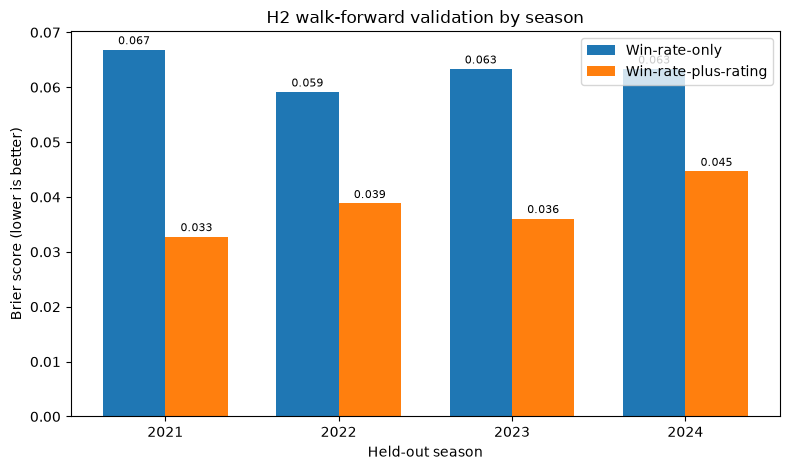

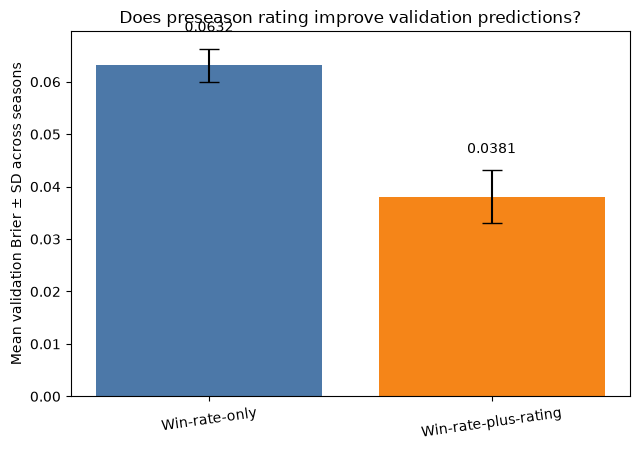

In [10]:
# Figure 1: Brier score for both candidates in each held-out season.
fig, ax = plt.subplots(figsize=(8, 4.8))
seasons = expected_validation_years
x = np.arange(len(seasons))
width = 0.36
for i, model_name in enumerate(FEATURES):
    values = [season_pivot.loc[season, model_name] for season in seasons]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=model_name)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x, seasons)
ax.set_xlabel("Held-out season")
ax.set_ylabel("Brier score (lower is better)")
ax.set_title("H2 walk-forward validation by season")
ax.legend()
fig.tight_layout()
validation_plot_path = FIGURES_DIR / "h2_validation_brier_by_season.png"
fig.savefig(validation_plot_path, dpi=160, bbox_inches="tight")
plt.show()

# Figure 2: mean score with one sample standard deviation across seasons.
fig, ax = plt.subplots(figsize=(6.5, 4.6))
means = [paired.loc[name, "mean_validation_brier"] for name in FEATURES]
spreads = [paired.loc[name, "validation_brier_sd"] for name in FEATURES]
bars = ax.bar(list(FEATURES), means, yerr=spreads, capsize=7, color=["#4C78A8", "#F58518"])
ax.bar_label(bars, fmt="%.4f", padding=10)
ax.set_ylabel("Mean validation Brier ± SD across seasons")
ax.set_title("Does preseason rating improve validation predictions?")
ax.tick_params(axis="x", rotation=8)
fig.tight_layout()
mean_plot_path = FIGURES_DIR / "h2_mean_validation_brier.png"
fig.savefig(mean_plot_path, dpi=160, bbox_inches="tight")
plt.show()


## 11. Final test on 2025 (selected candidate only)

We now refit **only the candidate selected from 2021–2024 validation** on the training seasons listed for `final_test_2025` (2015–2019 and 2021–2024). We predict the held-out 2025 outcomes and calculate one Brier score. Do not use this score to switch candidates or tune settings.


In [11]:
final_subset = fold_data[fold_data[FOLD_COL].eq(FINAL_TEST_FOLD)].copy()
final_train = final_subset[final_subset[ROLE_COL].eq("train")].copy()
final_test = final_subset[final_subset[ROLE_COL].eq("test")].copy()
selected_features = FEATURES[SELECTED_MODEL]

assert sorted(final_train["season"].unique().astype(int)) == FINAL_TRAIN_SEASONS
assert final_test["season"].nunique() == 1 and int(final_test["season"].iloc[0]) == 2025
assert set(final_train["season"]).isdisjoint(set(final_test["season"]))

final_test_model = make_model()
final_test_model.fit(final_train[selected_features], final_train[TARGET].astype(int))
p_final_train = final_test_model.predict_proba(final_train[selected_features])[:, 1]
p_final_test = final_test_model.predict_proba(final_test[selected_features])[:, 1]
final_train_brier = brier_score_loss(final_train[TARGET].astype(int), p_final_train)
final_test_brier = brier_score_loss(final_test[TARGET].astype(int), p_final_test)

final_test_predictions = final_test[["season", "team_id", TARGET]].copy()
final_test_predictions["model"] = SELECTED_MODEL
final_test_predictions["predicted_probability"] = p_final_test
final_test_predictions["brier_score"] = (
    final_test_predictions[TARGET] - final_test_predictions["predicted_probability"]
) ** 2
final_test_path = RESULTS_DIR / "h2_final_test_predictions.csv"
final_test_predictions.to_csv(final_test_path, index=False)

final_test_run_id = log_model_run(
    f"final_test_2025__{SELECTED_MODEL}__{EXECUTION_ID}",
    "final_test_2025_selected_model",
    {
        "model_name": SELECTED_MODEL,
        "features": ", ".join(selected_features),
        "target": TARGET,
        "training_seasons": ", ".join(map(str, FINAL_TRAIN_SEASONS)),
        "test_season": 2025,
        "selection_rule": "lowest mean validation Brier across 2021-2024; simple model wins exact tie",
        "scaler": "StandardScaler in Pipeline",
        "estimator": "LogisticRegression, L2, C=1.0, lbfgs, max_iter=2000",
        "execution_id": EXECUTION_ID,
    },
    {"train_brier": final_train_brier, "test_brier_2025": final_test_brier,
     "n_train": len(final_train), "n_test": len(final_test)},
    final_test_path,
    final_test_model,
)
print(f"Selected model: {SELECTED_MODEL}")
print(f"Training Brier (in-sample, through 2024): {final_train_brier:.4f}")
print(f"One-time 2025 final-test Brier: {final_test_brier:.4f} (n={len(final_test):,} team-seasons)")


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:10:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run final_test_2025__Win-rate-plus-rating__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/bfccf1cb61c0425c892af96c326d26de
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136
Selected model: Win-rate-plus-rating
Training Brier (in-sample, through 2024): 0.0383
One-time 2025 final-test Brier: 0.0425 (n=360 team-seasons)


## 12. Forecast tournament-success probabilities for 2026

There are no 2026 tournament outcomes in the data. We therefore do **not** calculate a Brier score for 2026. We refit both candidates on all labeled seasons through 2025 and produce forecasts for every active 2026 team. The separate forecast comparison for Team A and Team C is included because it was part of the H2 plan; it is not a validation or test result.


In [12]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\python.exe
1.6.0


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:24:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run forecast_2026__Win-rate-only__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/eb042630de26442a8ec1acbeaa0cecac
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136


c:\Users\SAMUE\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
2026/11/16 15:24:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run forecast_2026__Win-rate-plus-rating__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/cea9f30abd904d0ca758382feef8d2fe
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136


,brief_alias,team_name,model,forecast_probability_at_least_one_main_bracket_win
4,Team A,Ashford,Win-rate-only,0.2182
19,Team C,Calloway State,Win-rate-only,0.6024
364,Team A,Ashford,Win-rate-plus-rating,0.8007
379,Team C,Calloway State,Win-rate-plus-rating,0.0462


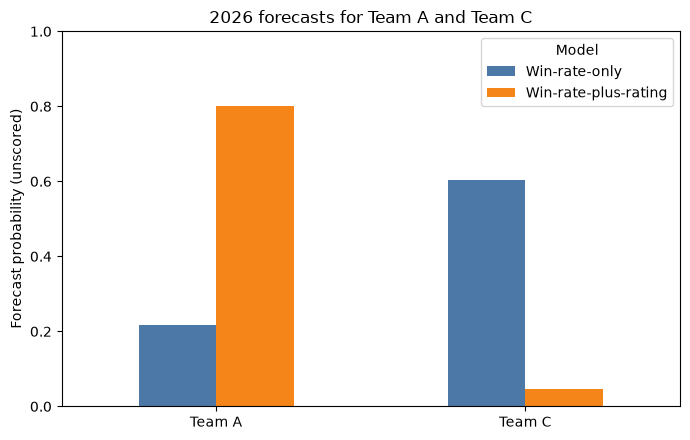

In [14]:
import sys
import joblib

print(sys.executable)
print(joblib.__version__)

teams = pd.read_csv(PROJECT_ROOT / "cleaned_data" / "teams.csv")[["team_id", "team_name", "brief_alias"]]
forecast_rows = []
forecast_run_ids = []
forecast_summary_rows = []

# The final prediction model for 2026 uses every available labeled season through 2025.
forecast_train = team_season_labeled[team_season_labeled["season"].between(2015, 2025)].copy()
forecast_train = forecast_train[forecast_train["season"].ne(2020)]
assert 2026 not in set(forecast_train["season"])
assert set(forecast_2026["season"].unique()) == {2026}

for model_name, feature_columns in FEATURES.items():
    model = make_model()
    model.fit(forecast_train[feature_columns], forecast_train[TARGET].astype(int))
    if model_name == SELECTED_MODEL:
        selected_model_dir = PROJECT_ROOT / "models" / "selected"
        selected_model_dir.mkdir(parents=True, exist_ok=True)
        h2_selected_model_path = selected_model_dir / "h2_win_rate_plus_rating_model.joblib"
        joblib.dump(model, h2_selected_model_path)
    probabilities = model.predict_proba(forecast_2026[feature_columns])[:, 1]
    predictions = forecast_2026[["season", "team_id"]].copy()
    predictions["team_name"] = predictions["team_id"].map(teams.set_index("team_id")["team_name"])
    predictions["brief_alias"] = predictions["team_id"].map(teams.set_index("team_id")["brief_alias"])
    predictions["model"] = model_name
    predictions["forecast_probability_at_least_one_main_bracket_win"] = probabilities
    forecast_rows.append(predictions)

    safe_model = model_name.lower().replace("+", "plus").replace("-", "_").replace(" ", "_")
    prediction_path = PREDICTIONS_DIR / f"{safe_model}__forecast_2026.csv"
    predictions.to_csv(prediction_path, index=False)
    train_probability = model.predict_proba(forecast_train[feature_columns])[:, 1]
    train_brier = brier_score_loss(forecast_train[TARGET].astype(int), train_probability)
    run_id = log_model_run(
        f"forecast_2026__{model_name}__{EXECUTION_ID}",
        "unscored_2026_forecast",
        {
            "model_name": model_name,
            "features": ", ".join(feature_columns),
            "target": TARGET,
            "training_seasons": "2015-2019, 2021-2025",
            "forecast_season": 2026,
            "forecast_rows": len(forecast_2026),
            "forecast_outcome_available": False,
            "scaler": "StandardScaler in Pipeline",
            "estimator": "LogisticRegression, L2, C=1.0, lbfgs, max_iter=2000",
            "execution_id": EXECUTION_ID,
        },
        {"train_brier_in_sample": train_brier, "n_train": len(forecast_train)},
        prediction_path,
        model,
    )
    forecast_run_ids.append(run_id)

forecast_predictions = pd.concat(forecast_rows, ignore_index=True)
forecast_path = RESULTS_DIR / "h2_2026_forecasts.csv"
forecast_predictions.to_csv(forecast_path, index=False)

focus = forecast_predictions[forecast_predictions["brief_alias"].isin(["Team A", "Team C"])].copy()
assert set(focus["brief_alias"]) == {"Team A", "Team C"}, "Expected Team A and Team C rows in 2026 forecast data."
focus_path = RESULTS_DIR / "h2_2026_team_a_team_c_forecasts.csv"
focus.to_csv(focus_path, index=False)
display(focus[["brief_alias", "team_name", "model", "forecast_probability_at_least_one_main_bracket_win"]].round(4))

fig, ax = plt.subplots(figsize=(7, 4.5))
pivot_forecast = focus.pivot(index="brief_alias", columns="model", values="forecast_probability_at_least_one_main_bracket_win")
pivot_forecast = pivot_forecast.reindex(["Team A", "Team C"])
pivot_forecast.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set_xlabel("")
ax.set_ylabel("Forecast probability (unscored)")
ax.set_ylim(0, 1)
ax.set_title("2026 forecasts for Team A and Team C")
ax.legend(title="Model")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
forecast_plot_path = FIGURES_DIR / "h2_2026_team_forecasts.png"
fig.savefig(forecast_plot_path, dpi=160, bbox_inches="tight")
plt.show()


## 13. Export all MLflow runs and create the H2 report

The next cell exports the MLflow run table and writes a concise report with the actual numbers from this execution. Review it alongside `results/results.md` and copy the checked H2 results and verdict into that main report before tagging M2.


In [15]:
mlflow_runs = export_mlflow_runs()
print(f"Validation runs in this execution: {len(validation_run_ids)}")
print(f"Forecast refit runs in this execution: {len(forecast_run_ids)}")
print("Final-test run ID:", final_test_run_id)
print("Exported MLflow rows (all recorded H2 runs):", len(mlflow_runs))

mean_only = float(validation_summary.loc[validation_summary["model"].eq("Win-rate-only"), "mean_validation_brier"].iloc[0])
mean_plus = float(validation_summary.loc[validation_summary["model"].eq("Win-rate-plus-rating"), "mean_validation_brier"].iloc[0])
sd_only = float(validation_summary.loc[validation_summary["model"].eq("Win-rate-only"), "validation_brier_sd"].iloc[0])
sd_plus = float(validation_summary.loc[validation_summary["model"].eq("Win-rate-plus-rating"), "validation_brier_sd"].iloc[0])
win_count_plus = int((season_pivot["Win-rate-plus-rating"] < season_pivot["Win-rate-only"]).sum())
if mean_plus < mean_only:
    verdict = "Supported: adding preseason rating produced the lower mean validation Brier score."
elif np.isclose(mean_plus, mean_only, atol=1e-12):
    verdict = "Unresolved: the two candidates had the same mean validation Brier score."
else:
    verdict = "Not supported: adding preseason rating did not lower the mean validation Brier score."

a_c_table = focus[["brief_alias", "model", "forecast_probability_at_least_one_main_bracket_win"]].pivot(
    index="model", columns="brief_alias", values="forecast_probability_at_least_one_main_bracket_win"
)

report_lines = [
    "# H2 Results — Preseason Rating and Tournament Success", "",
    f"**Execution ID:** `{EXECUTION_ID}`", "",
    "## Validation results", "",
    "Both logistic-regression candidates used the same walk-forward folds (2021–2024), scaling pipeline, and Brier score. The only planned difference was adding `preseason_rating` to the second model.", "",
    "| Model | 2021 Brier | 2022 Brier | 2023 Brier | 2024 Brier | Mean validation Brier | Spread (SD) | Mean train–validation gap |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for _, row in validation_summary.iterrows():
    report_lines.append(
        f"| {row['model']} | " + " | ".join(f"{row[f'brier_{year}']:.4f}" for year in expected_validation_years)
        + f" | {row['mean_validation_brier']:.4f} | {row['validation_brier_sd']:.4f} | {row['mean_train_validation_gap']:.4f} |"
    )
report_lines += [
    "", f"**Model selected from validation:** {SELECTED_MODEL}. It had the lower mean Brier score; an exact tie defaults to the simpler win-rate-only candidate.",
    f"**Season-by-season check:** Win-rate-plus-rating had the lower Brier score in {win_count_plus} of 4 validation seasons.",
    "", "## Final test", "",
    f"The selected model was refit on 2015–2019 and 2021–2024 and scored once on the held-out 2025 team-seasons. Its final-test Brier score was **{final_test_brier:.4f}** (n={len(final_test):,}). The test score was not used to select the model.",
    "", "## 2026 forecasts (not scored)", "",
    "Both models were refit on labeled seasons through 2025. Because 2026 tournament outcomes are unavailable, these probabilities are forecasts and have no Brier score.",
    "", "| Model | Team A forecast probability | Team C forecast probability |", "|---|---:|---:|",
]
for model_name in FEATURES:
    report_lines.append(
        f"| {model_name} | {a_c_table.loc[model_name, 'Team A']:.4f} | {a_c_table.loc[model_name, 'Team C']:.4f} |"
    )
report_lines += [
    "", "## H2 verdict", "", verdict,
    f"The mean validation Brier scores were {mean_only:.4f} for win-rate-only (SD {sd_only:.4f}) and {mean_plus:.4f} for win-rate-plus-rating (SD {sd_plus:.4f}).",
    "", "## Files", "",
    "- `h2_validation_results.csv` and `h2_validation_fold_scores.csv` — validation scores, spread, and train–validation gaps.",
    "- `h2_validation_predictions.csv` and `h2_final_test_predictions.csv` — saved team-season predictions and actual labels.",
    "- `h2_2026_forecasts.csv` and `h2_2026_team_a_team_c_forecasts.csv` — unscored 2026 forecasts.",
    "- `h2_mlflow_runs.csv` — exported MLflow run names, IDs, parameters, metrics, and artifact locations.",
    "- `figures/` — validation and forecast plots.",
    "- `mlflow/H2/` — local MLflow database and artifacts; these are reproducibility files, while the exported CSV run table is the compact report artifact.",
]
report_text = "\n".join(report_lines)
report_path = RESULTS_DIR / "h2_results_summary.md"
report_path.write_text(report_text, encoding="utf-8")


Validation runs in this execution: 8
Forecast refit runs in this execution: 2
Final-test run ID: bfccf1cb61c0425c892af96c326d26de
Exported MLflow rows (all recorded H2 runs): 23


2366

## Upload the complete H2 outputs to MLflow

The H2 results, figures, predictions, forecasts, prepared tables, selected model file, and report remain in their project folders. This final cell also uploads those files to one MLflow artifact bundle on the course server. The per-model runs above are already on the server with their metrics, prediction files, and fitted pipelines.


In [16]:
# Export the server run table locally, then collect every H2 deliverable for one artifact bundle.
h2_run_table = export_mlflow_runs(RESULTS_DIR / "h2_mlflow_runs.csv")
h2_selected_run_name = f"forecast_2026__{SELECTED_MODEL}__{EXECUTION_ID}"
h2_selected_run_id = REMOTE_RUN_IDS.get(h2_selected_run_name)
if h2_selected_run_id is None:
    raise RuntimeError(f"The selected H2 forecast model run was not found: {h2_selected_run_name}")

h2_models_dir = PROJECT_ROOT / "models" / "selected"
h2_models_dir.mkdir(parents=True, exist_ok=True)
h2_run_ids_path = h2_models_dir / "model_run_ids.json"
h2_run_ids = json.loads(h2_run_ids_path.read_text(encoding="utf-8")) if h2_run_ids_path.exists() else {}
h2_run_ids["H2"] = h2_selected_run_id
h2_run_ids_path.write_text(json.dumps(h2_run_ids, indent=2) + "\n", encoding="utf-8")


def collect_h2_artifacts():
    collected = []
    folders = [(RESULTS_DIR, "results/H2"), (PROJECT_ROOT / "figures", "figures"),
               (PROJECT_ROOT / "prepared_data" / "H2", "prepared_data/H2"),
               (h2_models_dir, "models/selected")]
    for folder, prefix in folders:
        if folder.exists():
            for path in folder.rglob("*"):
                if path.is_file():
                    collected.append((path, f"{prefix}/{path.relative_to(folder).as_posix()}"))
    report = PROJECT_ROOT / "results" / "results.md"
    if report.exists():
        collected.append((report, "results/results.md"))
    return collected


h2_artifacts = collect_h2_artifacts()
activate_tracking()
with mlflow.start_run(run_name=f"H2_complete_outputs__{EXECUTION_ID}") as h2_bundle:
    mlflow.set_tags({"hypothesis": "H2", "run_type": "complete_output_bundle",
                     "execution_id": EXECUTION_ID})
    mlflow.log_params({"artifact_file_count": len(h2_artifacts),
                       "included": "results, predictions, forecasts, figures, prepared data, selected model"})
    for local_path, artifact_path in h2_artifacts:
        mlflow.log_artifact(str(local_path), artifact_path=artifact_path.rsplit("/", 1)[0])
    h2_bundle_run_id = h2_bundle.info.run_id

# Refresh the exported run table so it includes the bundle run, then attach the final CSV and IDs to the bundle.
h2_run_table = export_mlflow_runs(RESULTS_DIR / "h2_mlflow_runs.csv")
client = MlflowClient(tracking_uri=MLFLOW_TRACKING_URI)
client.log_artifact(h2_bundle_run_id, str(RESULTS_DIR / "h2_mlflow_runs.csv"), artifact_path="run_tables")
client.log_artifact(h2_bundle_run_id, str(h2_run_ids_path), artifact_path="models/selected")
print("H2 MLflow server runs:", len(h2_run_table))
print("H2 selected-model run ID:", h2_selected_run_id)
print("H2 full-output bundle run ID:", h2_bundle_run_id)
print("H2 files remain in:", RESULTS_DIR)


🏃 View run H2_complete_outputs__4d84b5b07d at: http://10.0.100.20:5000/#/experiments/136/runs/04e07218145d45ea853ee172c9eccf46
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/136
H2 MLflow server runs: 24
H2 selected-model run ID: cea9f30abd904d0ca758382feef8d2fe
H2 full-output bundle run ID: 04e07218145d45ea853ee172c9eccf46
H2 files remain in: c:\Users\SAMUE\Downloads\CSC_400_series\CSC 4913\Project\final-project-main\Topic4_Sports_Analytics_The_Unbeatable_Underdog\CSC-4913-Project-4\results\H2
